# PortfolioPilot - 04 Dimension reduction (PCA)

**Run the cells in order, top to bottom.** Install the package first (`pip install -e .` from the project root).

Rule for M3: the test sets are created in notebook 01 and then never explored. Every statistic, cap,
table and figure uses **training data only**.

## Step 1 - Setting up

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from portfolio_pilot.config import Results, ensure_output_dirs, load_config

cfg = load_config()
ensure_output_dirs(cfg)
P, SEED = cfg["paths"], cfg["seed"]
results = Results(P["numbers_file"])    # every count quoted in the report; saved in the last cell
np.random.seed(SEED)

plt.rcParams.update({"figure.dpi": 110, "font.size": 9,
                     "axes.spines.top": False, "axes.spines.right": False})

def save_fig(fig, name):
    fig.tight_layout()
    fig.savefig(P["figures_dir"] / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

## Step 2 - Features (caps fitted on training data only)

In [2]:
from portfolio_pilot.features import build_partition_features
from portfolio_pilot.prepare import fit_caps
from portfolio_pilot.split import load_partitions

hh = pd.read_csv(P["processed_dir"] / "scf_clean.csv")
parts = load_partitions(hh, P["processed_dir"] / "scf_split_ids.csv")
caps = fit_caps(parts["train"], cfg["scf"]["cap_quantile"], results)     # caps come from training households only
feats = build_partition_features(parts, caps)
tr = feats["train"]
results["features"]

{'caps_from_train': {'dti': 7.322105263125945,
  'liq_to_income': 4.421218403259946},
 'train_ratio_undefined_income_le_0': 18,
 'train_dti_above_cap': 31,
 'train_lti_above_cap': 31,
 'train_fin_zero': 34}

## Step 3 - PCA on the SCF clustering variables
Fitted on a standardized, survey-weighted resample of the training households.

In [3]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

from portfolio_pilot.features import CLUSTER_FEATURES
from portfolio_pilot.prepare import weighted_resample

THRESHOLD = cfg["pca_threshold"]
Xp = weighted_resample(tr, SEED)[CLUSTER_FEATURES].to_numpy(float)
pca_scf = PCA(random_state=SEED).fit(StandardScaler().fit_transform(Xp))
evr_scf = pca_scf.explained_variance_ratio_
results.note("pca_scf", "explained", evr_scf.tolist())
results.note("pca_scf", "cumulative", np.cumsum(evr_scf).tolist())
results.note("pca_scf", "n_to_threshold", int(np.searchsorted(np.cumsum(evr_scf), THRESHOLD) + 1))
results.note("pca_scf", "n_eigen_gt_1", int((pca_scf.explained_variance_ > 1).sum()))
load_scf = pd.DataFrame(pca_scf.components_.T, index=CLUSTER_FEATURES,
                        columns=[f"PC{i+1}" for i in range(len(CLUSTER_FEATURES))])
load_scf.to_csv(P["tables_dir"] / "pca_scf_loadings.csv")
print("Cumulative variance:", np.cumsum(evr_scf).round(3))
load_scf.round(3)

Cumulative variance: [0.274 0.513 0.669 0.802 0.908 1.   ]


,PC1,PC2,PC3,PC4,PC5,PC6
age,0.302,0.570,0.346,-0.144,-0.345,0.569
risk_willingness,0.381,-0.492,-0.408,0.213,0.062,0.630
asinh_networth,0.579,0.097,0.202,-0.229,0.737,-0.139
asinh_dti,-0.026,-0.421,0.798,0.426,0.002,0.060
asinh_liq_to_income,0.493,0.262,-0.168,0.662,-0.246,-0.402
equity_share,0.430,-0.421,0.089,-0.512,-0.523,-0.307


## Step 4 - PCA on ETF returns and the scree plot

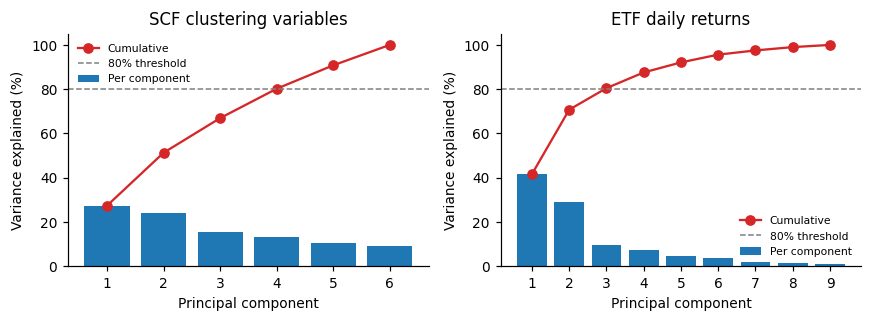

ETF cumulative variance: [0.416 0.707 0.805 0.876 0.921 0.956 0.975 0.99  1.   ]


,PC1,PC2,PC3
SPY,0.483,0.013,-0.179
VEA,0.489,0.053,-0.079
VWO,0.456,0.076,-0.019
AGG,-0.014,0.549,-0.256
TLT,-0.237,0.501,-0.178
TIP,-0.037,0.535,0.004
VNQ,0.403,0.119,-0.303
GLD,0.027,0.367,0.628
DBC,0.315,0.067,0.614


In [4]:
TICKERS = cfg["etf"]["tickers"]
etr = pd.read_csv(P["processed_dir"] / "etf_returns_train.csv", index_col=0, parse_dates=True)

pca_etf = PCA(random_state=SEED).fit(StandardScaler().fit_transform(etr))
evr_etf = pca_etf.explained_variance_ratio_
results.note("pca_etf", "explained", evr_etf.tolist())
results.note("pca_etf", "cumulative", np.cumsum(evr_etf).tolist())
results.note("pca_etf", "n_to_threshold", int(np.searchsorted(np.cumsum(evr_etf), THRESHOLD) + 1))
load_etf = pd.DataFrame(pca_etf.components_.T, index=TICKERS, columns=[f"PC{i+1}" for i in range(len(TICKERS))])
load_etf.to_csv(P["tables_dir"] / "pca_etf_loadings.csv")

fig, axes = plt.subplots(1, 2, figsize=(8, 3))
for ax, (title, evr) in zip(axes, [("SCF clustering variables", evr_scf), ("ETF daily returns", evr_etf)]):
    xs = np.arange(1, len(evr) + 1)
    ax.bar(xs, evr * 100, label="Per component")
    ax.plot(xs, np.cumsum(evr) * 100, marker="o", color="C3", label="Cumulative")
    ax.axhline(THRESHOLD * 100, ls="--", color="grey", lw=1, label=f"{int(THRESHOLD*100)}% threshold")
    ax.set_xticks(xs)
    ax.set_xlabel("Principal component")
    ax.set_ylabel("Variance explained (%)")
    ax.set_title(title)
    ax.legend(frameon=False, fontsize=7)
save_fig(fig, "fig08_pca_scree")
print("ETF cumulative variance:", np.cumsum(evr_etf).round(3))
load_etf.iloc[:, :3].round(3)

## Save the numbers quoted in the report

In [5]:
results.save()
print("Saved", P["numbers_file"])

Saved C:\Users\jp\Documents\DAE\7275\Pilot\Portfolio-Pilot\reports\numbers.json
